# Used Vehicle Data: Exploratory Data Analysis

**Dataset:** Kaggle used-vehicle listings (`car_data_cleaned.csv`), 3,577 cars  
**Goal:** Understand how selling price relates to car age, kilometres driven, owner history, seller type, fuel type and transmission.

**Sections:** 1) Selling Price Distribution · 2) Car Age vs KM Driven · 3) Selling Price vs KM Driven · 4) Car Age vs Owner / Selling Price vs Seller Type · 5) Average Price by Fuel Type and Transmission · 6) Correlation Heatmap · Key Findings · Conclusion

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

file_path = Path("..") / "Data" /"car_data_cleaned.csv"
df = pd.read_csv(file_path)
display(df.head())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12


## 1). Sellingprice Distribution

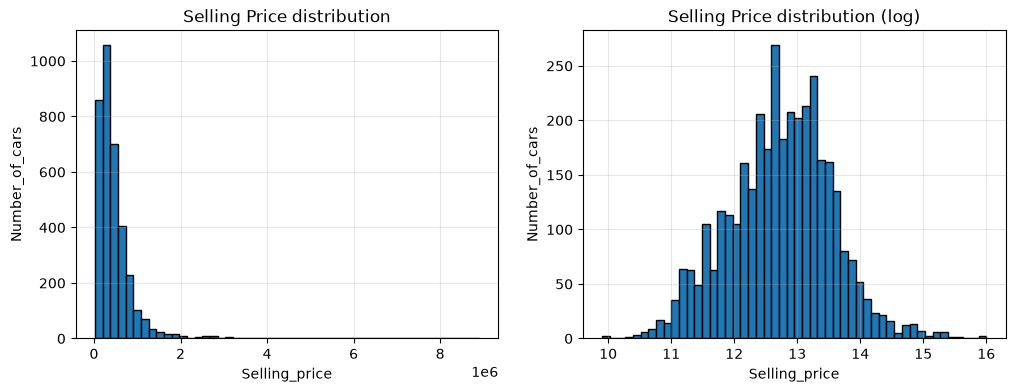

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["selling_price"], bins=50, edgecolor = "black")
axes[0].set_title("Selling Price distribution")
axes[0].set_xlabel("Selling_price")
axes[0].set_ylabel("Number_of_cars")
axes[0].grid(True, alpha=0.3)
axes[1].hist(np.log1p(df["selling_price"]), bins=50, edgecolor = "black")
axes[1].set_title("Selling Price distribution (log)")
axes[1].set_xlabel("Selling_price")
axes[1].set_ylabel("Number_of_cars")
axes[1].grid(True, alpha=0.3)

plt.show()

#### Analysis: Selling Price Distribution

*Prices are assumed to be in Indian rupees (₹). The right-hand chart plots `log1p(selling_price)`, so x = 12 ≈ ₹0.16M, 13 ≈ ₹0.44M, 14 ≈ ₹1.2M and 16 ≈ ₹8.9M.*

- **Strongly right-skewed.** In the raw histogram most cars are bunched at the low end (the tallest bars lie between roughly ₹0 and ₹0.7M), while a thin tail stretches out to about ₹9M. Only a handful of listings are priced above ₹2M.
- **Mean is pulled above the median.** Because of that tail, a few luxury cars inflate the average, so the median is the safer "typical price" for this data (and is what the later sections use).
- **The log transform fixes the shape.** After the transform the distribution is roughly bell-shaped, centred at about 12.5–13.3 (≈ ₹0.27M–₹0.6M). There is a shoulder around 11–11.5 (≈ ₹60k–₹100k, old budget cars) and a thinner right tail beyond 14 (> ₹1.2M, premium cars).
- **Small spikes** in the log histogram are most likely caused by round-number asking prices (e.g. ₹250k, ₹300k, ₹450k) rather than real structure.
- **Implication.** Use `log(selling_price)` for modelling and for correlation checks, and treat the > ₹2M listings as a separate premium segment rather than as errors.

## 2). Car age vs km driven

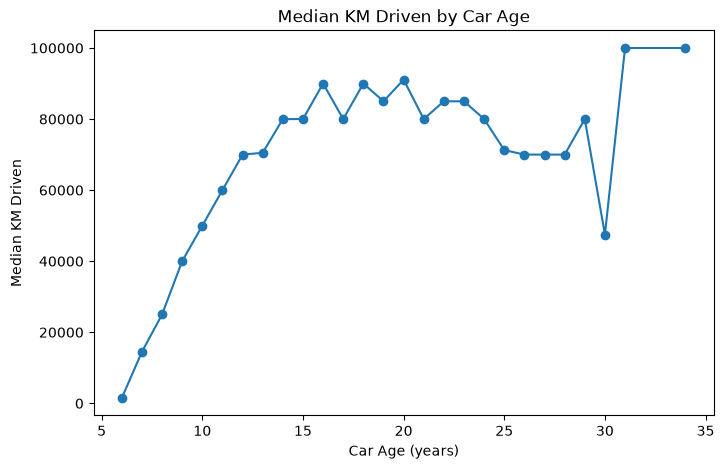

In [3]:
df.groupby("car_age")["km_driven"].median().plot(kind="line", marker="o", figsize=(8, 5))
plt.title("Median KM Driven by Car Age")
plt.xlabel("Car Age (years)")
plt.ylabel("Median KM Driven")
plt.show()


#### Analysis: Median KM Driven by Car Age

*`car_age` is calculated against 2026 (e.g. model year 2020 → 6 years), so every car in the data set is at least 6 years old.*

- **Steep climb in the early years.** Median mileage rises from ≈ 1.5k km at age 6 to ≈ 40k km at age 9 and ≈ 70k km at age 12, i.e. roughly 10–15k km added per year.
- **Plateau after ~14 years.** From about age 14 to 24 the median stays flat at ≈ 80–90k km and then eases to ≈ 70k km around ages 25–28. Older cars are therefore not driven proportionally more; plausibly very old cars are used less, and extremely high-mileage ones may have been scrapped before they could be listed (survivorship effect).
- **The right-hand side is noisy.** The dip to ≈ 47k km at age 30 and the jump to 100k km at ages 31 and 34 are most likely small-sample noise (very few cars per age), so they should not be read as real trends.
- **Link to the heatmap.** The moderate positive correlation between age and km driven (0.42 in Section 6) matches this picture: mileage grows with age, but it saturates.

In [4]:
age_median = df["car_age"].median()
km_median = df["km_driven"].median()

df["km_per_year"] = df["km_driven"] / df["car_age"].replace(0, 1)  # avoid division by zero


best_candidates = df[df["car_age"] > age_median].nsmallest(5, "km_per_year")


worst_candidates = df[df["car_age"] < age_median].nlargest(5, "km_per_year")

print("Best candidates:")
display(best_candidates)

print("\nWorst candidates :")
display(worst_candidates)


Best candidates:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,km_per_year
946,Mahindra Jeep CJ 500 DI,2006,575000,1001,Diesel,Dealer,Manual,First Owner,20,50.050000
1421,Mahindra Jeep Classic,1999,170000,2020,Diesel,Individual,Manual,Second Owner,27,74.814815
1829,Maruti Alto LXI,2003,60000,5000,Petrol,Individual,Manual,Second Owner,23,217.391304
2259,Ford Ikon 1.3 Flair,2005,61000,4637,Petrol,Individual,Manual,Second Owner,21,220.809524
2654,Maruti Zen Estilo LXI BSIII,2007,275000,10211,Petrol,Individual,Manual,First Owner,19,537.421053



Worst candidates :


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,km_per_year
510,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner,10,56000.000000
2663,Maruti Swift Dzire VDI,2014,450000,260000,Diesel,Individual,Manual,Second Owner,12,21666.666667
3353,Toyota Innova 2.5 VX (Diesel) 8 Seater,2014,1030000,250000,Diesel,Individual,Manual,Second Owner,12,20833.333333
1502,Toyota Innova 2.5 GX (Diesel) 7 Seater,2014,650000,244000,Diesel,Individual,Manual,First Owner,12,20333.333333
145,Maruti Wagon R LXI,2020,240000,120000,Petrol,Individual,Manual,First Owner,6,20000.000000


#### Analysis: Best and Worst Candidates by Usage per Year

`km_per_year = km_driven / car_age` (a car aged 0 would be treated as 1 year). *Best* = cars older than the median age with the lowest km per year; *worst* = cars younger than the median age with the highest.

- **The "best" candidates look suspiciously low.** They show only ≈ 50–540 km per year, for example a 2006 Mahindra Jeep CJ 500 DI with 1,001 km (≈ 50 km/yr), a 1999 Mahindra Jeep Classic with 2,020 km, a 2003 Maruti Alto LXI with 5,000 km and a 2005 Ford Ikon with 4,637 km. A garage-kept or collector vehicle is possible, but an odometer reset or data-entry error is more likely, so these rows should be verified before being treated as bargains.
- **The "worst" candidates are heavy-use vehicles.** Four of the five are diesels and all five are manual cars, running ≈ 20k–56k km per year. The two Toyota Innovas and the Maruti Swift Dzire are typical taxi/fleet models, which fits that usage.
- **One extreme outlier.** The 2016 Maruti SX4 S-Cross with 560,000 km in 10 years (≈ 56,000 km/yr, over 150 km every single day) is far beyond the rest. It is also the extreme point in the scatter plot of Section 3 and should be checked or capped.
- **Takeaway.** `km_per_year` is a useful usage-intensity feature, but its extremes contain probable data errors.

## 3).Selling-Price vs Km Driven


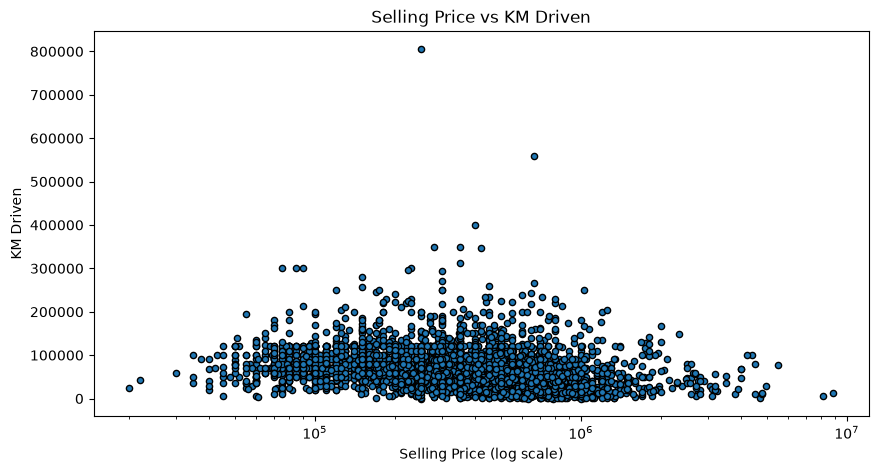

In [5]:
plt.figure(figsize=(10, 5))
plt.scatter(df["selling_price"], df["km_driven"], s= 20, edgecolor="black")
plt.xscale("log")

plt.title("Selling Price vs KM Driven")
plt.xlabel("Selling Price (log scale)")
plt.ylabel("KM Driven")
plt.show()

#### Analysis: Selling Price vs KM Driven

- **No clear linear relationship.** The scatter is a wide cloud: most cars lie between ≈ ₹100k and ₹1M and below ≈ 150k km, and at almost every price level the km range is very wide. Mileage alone is a weak predictor of price (r ≈ −0.19 in Section 6).
- **A mild downward tilt at the top.** The ceiling of the cloud falls as price rises: cars above 200k km are almost all priced below ≈ ₹1.5M, and above ≈ ₹2M practically every car has under ≈ 150k km. Expensive cars tend to be sold younger and less used.
- **Cheap cars are not always high-km.** Below ₹100k the mileage ranges from almost zero to ≈ 300k km, so low prices are driven by age and model rather than by the odometer.
- **Outliers.** One car shows ≈ 800k km at ≈ ₹250k and another ≈ 560k km at ≈ ₹660k (the SX4 from Section 2), both probably data-entry errors or extreme commercial use. At the far right, a few ₹8M+ cars have very low mileage (~10k km).
- **Chart note.** The log x-axis spreads out the skewed prices, but the dense middle still overplots; smaller/transparent markers or a hexbin plot would show the density better.

In [6]:
sp_median = df["selling_price"].median()
km_median = df["km_driven"].median()

best_candidates = df[
    (df["selling_price"] < sp_median) & 
    (df["km_driven"] < km_median)
].nsmallest(5, "selling_price")   


worst_candidates = df[
    (df["selling_price"] > sp_median) & 
    (df["km_driven"] > km_median)
].nlargest(5, "selling_price")    

print("Best candidates:")
display(best_candidates)

print("\nWorst candidates :")
display(worst_candidates)


Best candidates:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,km_per_year
2257,Ford Ikon 1.6 ZXI NXt,2005,20000,25000,Petrol,Individual,Manual,Second Owner,21,1190.476190
2132,Ford Ikon 1.4 ZXi,2000,22000,42743,Petrol,Dealer,Manual,Third Owner,26,1643.961538
1659,Tata Nano LX SE,2012,35000,35000,Petrol,Individual,Manual,Third Owner,14,2500.000000
2410,Tata Nano Std BSII,2009,35000,50000,Petrol,Individual,Manual,Third Owner,17,2941.176471
124,Maruti 800 Std,1998,40000,40000,Petrol,Individual,Manual,Fourth & Above Owner,28,1428.571429



Worst candidates :


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,km_per_year
3341,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Dealer,Automatic,First Owner,10,7735.000000
3385,Volvo XC 90 D5 Inscription BSIV,2017,4500000,80000,Diesel,Individual,Automatic,First Owner,9,8888.888889
524,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,2014,4400000,100000,Diesel,Individual,Automatic,Second Owner,12,8333.333333
3260,Land Rover Range Rover 4.4 Diesel LWB Vogue SE,2010,4200000,100000,Diesel,Dealer,Automatic,First Owner,16,6250.000000
655,Land Rover Discovery Sport TD4 HSE 7S,2018,4000000,68000,Diesel,Individual,Automatic,First Owner,8,8500.000000


#### Analysis: Best and Worst Candidates by Price and KM

*Best* = price and km both below the median, cheapest first; *worst* = price and km both above the median, most expensive first.

- **The cheapest low-km cars are old, small budget models.** All five "best" rows are petrol, manual cars: Ford Ikon (2000, 2005), Tata Nano (2009, 2012) and a 1998 Maruti 800, priced at ₹20k–₹40k with 25k–50k km. They are 14–28 years old, all multi-owner (second to fourth+), and four of the five are sold by individuals. Age, brand and ownership history clearly outweigh low mileage in setting the price.
- **The priciest high-km cars are premium diesel SUVs.** All five "worst" rows are automatic diesels: Mercedes GLS 350d (₹5.5M), Volvo XC90 (₹4.5M), Mercedes GL-Class (₹4.4M), Range Rover (₹4.2M) and Land Rover Discovery Sport (₹4.0M). They have 68k–100k km and are 8–16 years old, yet still sell for several million rupees.
- **Takeaway.** Brand and segment dominate price; above-median mileage does not make a luxury SUV cheap. This is why `km_driven` has only a weak correlation with price, and these are also the cars where value for money is hardest to judge.

## 4).Car age vs owner

,median,count
owner,,
First Owner,11.0,2218
Fourth & Above Owner,18.0,75
Second Owner,15.0,978
Test Drive Car,6.0,17
Third Owner,16.0,289


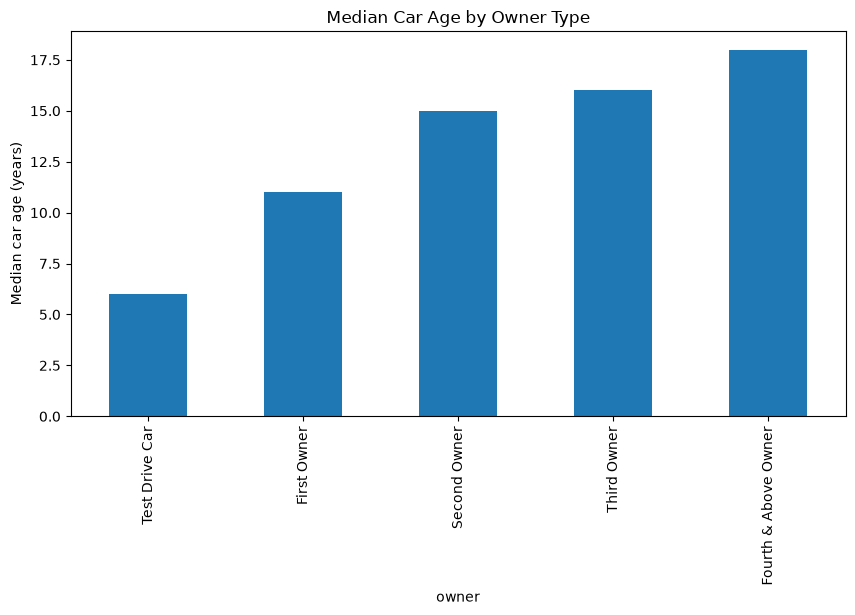

In [7]:
stats = df.groupby("owner")["car_age"].agg(["median", "count"])
display(stats)  
stats["median"].sort_values().plot(kind="bar", figsize=(10, 5))
plt.title("Median Car Age by Owner Type")
plt.ylabel("Median car age (years)")
plt.show()

#### Analysis: Median Car Age by Owner Type

| Owner type | Median age (years) | Cars | Share of listings |
|---|---|---|---|
| Test Drive Car | 6 | 17 | 0.5% |
| First Owner | 11 | 2,218 | 62.0% |
| Second Owner | 15 | 978 | 27.3% |
| Third Owner | 16 | 289 | 8.1% |
| Fourth & Above Owner | 18 | 75 | 2.1% |

- **Age rises steadily with the number of owners:** 6 → 11 → 15 → 16 → 18 years. The biggest step is from first to second owner (+4 years); later steps are smaller (+1, +2). This is intuitive: the longer a car exists, the more often it changes hands.
- **Test-drive cars are the youngest** (6 years, the minimum age in the data set), as expected for demo vehicles that are sold after a short working life.
- **The data is dominated by first- and second-owner cars** (about 89% of the 3,577 listings). The Test Drive (17 cars) and Fourth & Above (75 cars) groups are small, so their medians are less reliable.
- **Owner count and age are confounded.** Multi-owner cars are also older, cheaper and have higher mileage, so the number of owners should not be read as an independent cause of a lower price without controlling for age.

## 4b). Selling Price vs Seller Type

,median,count
seller_type,,
Dealer,484999.0,712
Individual,303500.0,2832
Trustmark Dealer,750000.0,33


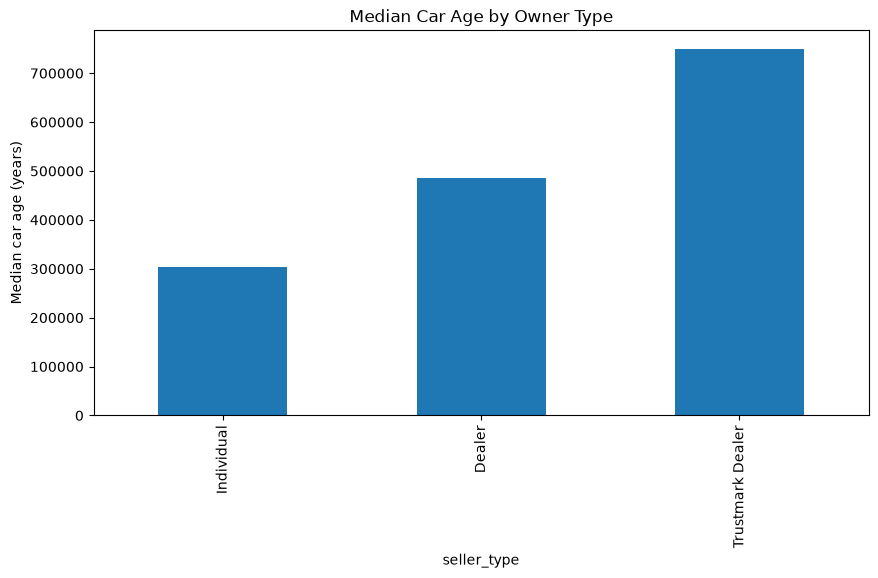

In [8]:
stats = df.groupby("seller_type")["selling_price"].agg(["median", "count"])
display(stats)  
stats["median"].sort_values().plot(kind="bar", figsize=(10, 5))
plt.title("Median Car Age by Owner Type")
plt.ylabel("Median car age (years)")
plt.show()

#### Analysis: Median Selling Price by Seller Type

> **Note on the chart labels:** the title and y-axis label of this chart say "Median Car Age by Owner Type … (years)", but the code plots the median **selling price** by `seller_type` (the y-axis runs to ₹700k+). Replacing the two label lines with `plt.title("Median Selling Price by Seller Type")` and `plt.ylabel("Median selling price (₹)")` makes the chart match the data. The analysis below describes the values actually plotted.

| Seller type | Median selling price (₹) | Cars | Share of listings |
|---|---|---|---|
| Individual | 303,500 | 2,832 | 79.2% |
| Dealer | 484,999 | 712 | 19.9% |
| Trustmark Dealer | 750,000 | 33 | 0.9% |

- **Clear ordering: Individual < Dealer < Trustmark Dealer.** The median dealer price is about 1.6× the median individual price, and Trustmark Dealer is about 2.5×.
- **Private sellers dominate the market** (≈ 79% of listings) and sell the cheapest cars, which fits the earlier findings that most listings are older, lower-priced cars.
- **Possible explanations (hypotheses to test):** dealers tend to stock newer or higher-value cars and add a margin for reconditioning, while the Trustmark Dealer category (presumably certified/authorised dealers) probably handles premium, certified stock. Comparing `car_age` and `fuel`/`transmission` by `seller_type` would confirm this.
- **Caution:** only 33 cars are Trustmark Dealer listings, so that bar is based on a very small sample.

,median,count
owner,,
First Owner,11.0,2218
Fourth & Above Owner,18.0,75
Second Owner,15.0,978
Test Drive Car,6.0,17
Third Owner,16.0,289


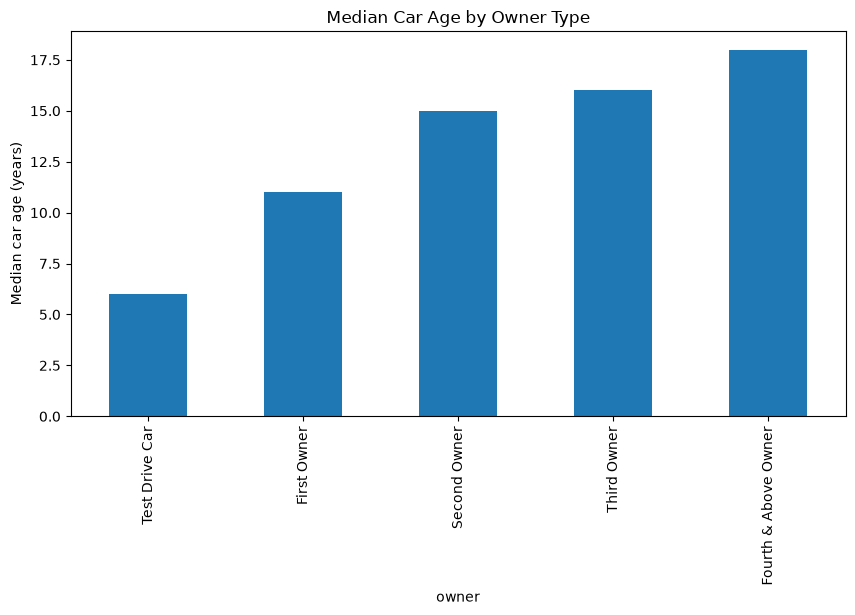

In [9]:
stats = df.groupby("owner")["car_age"].agg(["median", "count"])
display(stats)  
stats["median"].sort_values().plot(kind="bar", figsize=(10, 5))
plt.title("Median Car Age by Owner Type")
plt.ylabel("Median car age (years)")
plt.show()

,median,count
owner,,
First Owner,11.0,2218
Fourth & Above Owner,18.0,75
Second Owner,15.0,978
Test Drive Car,6.0,17
Third Owner,16.0,289


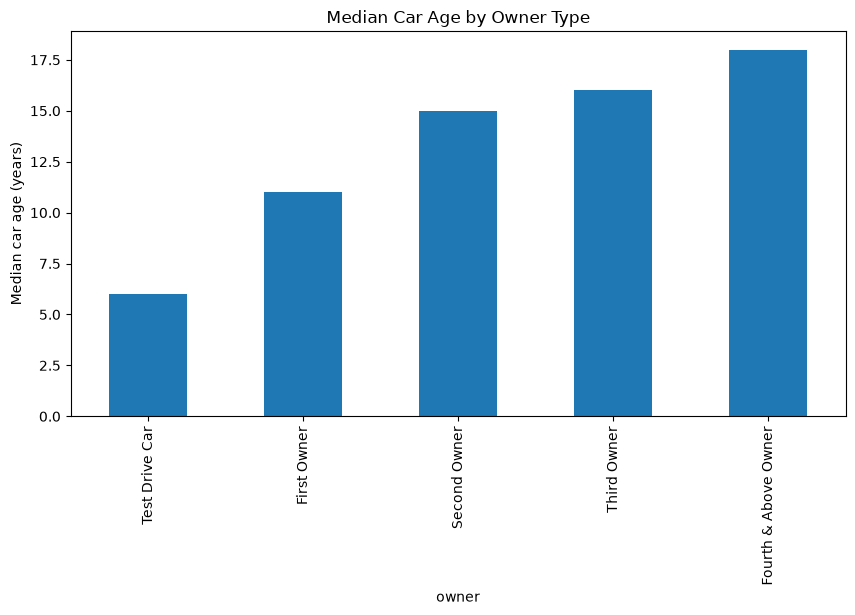

In [10]:
stats = df.groupby("owner")["car_age"].agg(["median", "count"])
display(stats)  
stats["median"].sort_values().plot(kind="bar", figsize=(10, 5))
plt.title("Median Car Age by Owner Type")
plt.ylabel("Median car age (years)")
plt.show()

## 5).Average Selling Price by Fuel Type (Automatic vs Manual)

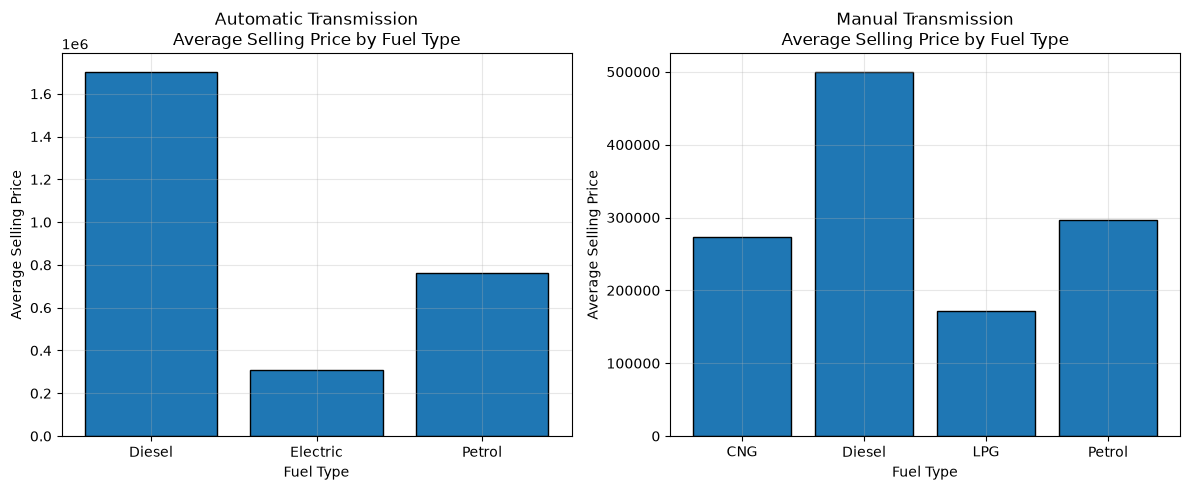

In [11]:

auto_avg = df[df["transmission"] == "Automatic"].groupby("fuel")["selling_price"].mean()
manual_avg = df[df["transmission"] == "Manual"].groupby("fuel")["selling_price"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(auto_avg.index, auto_avg.values, edgecolor="black")
axes[0].set_title("Automatic Transmission\nAverage Selling Price by Fuel Type")
axes[0].set_xlabel("Fuel Type")
axes[0].set_ylabel("Average Selling Price")
axes[0].grid(True, alpha=0.3)

axes[1].bar(manual_avg.index, manual_avg.values, edgecolor="black")
axes[1].set_title("Manual Transmission\nAverage Selling Price by Fuel Type")
axes[1].set_xlabel("Fuel Type")
axes[1].set_ylabel("Average Selling Price")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Analysis: Average Selling Price by Fuel Type (Automatic vs Manual)

Approximate bar heights: **Automatic** – Diesel ≈ ₹1.70M, Petrol ≈ ₹0.76M, Electric ≈ ₹0.31M. **Manual** – Diesel ≈ ₹0.50M, Petrol ≈ ₹0.30M, CNG ≈ ₹0.27M, LPG ≈ ₹0.17M.

- **Diesel is the most expensive fuel in both groups.** Automatic diesel is about 2.2× automatic petrol, and manual diesel about 1.7× manual petrol.
- **Automatics carry a large premium.** Automatic diesel (≈ ₹1.7M) averages about 3.4× manual diesel (≈ ₹0.5M), and automatic petrol about 2.6× manual petrol.
- **This is probably a segment effect rather than a pure fuel or gearbox effect.** Automatic diesels appear to be concentrated in luxury SUVs (see the "worst candidates" in Section 3), so brand, size and features are likely driving the gap. Comparing models within the same segment would isolate the real effect.
- **Alternative fuels are cheapest.** Among manuals, CNG and LPG average less than petrol, with LPG the lowest at ≈ ₹0.17M, which points to older budget cars.
- **Electric (automatic) ≈ ₹0.31M** is the lowest automatic bar, but electric cars are rare in a used-car list, so this bar probably rests on very few cars. Check the group size before drawing conclusions.
- **Reading notes.** The two panels use different y-axes (up to ≈ ₹1.7M vs ≈ ₹0.5M), and averages are pulled up by expensive outliers, so a median and the number of cars per bar would make the comparison more robust. Automatic CNG/LPG and manual electric cars do not appear, meaning those combinations are absent from the data.

## 6).Correlation Heatmap

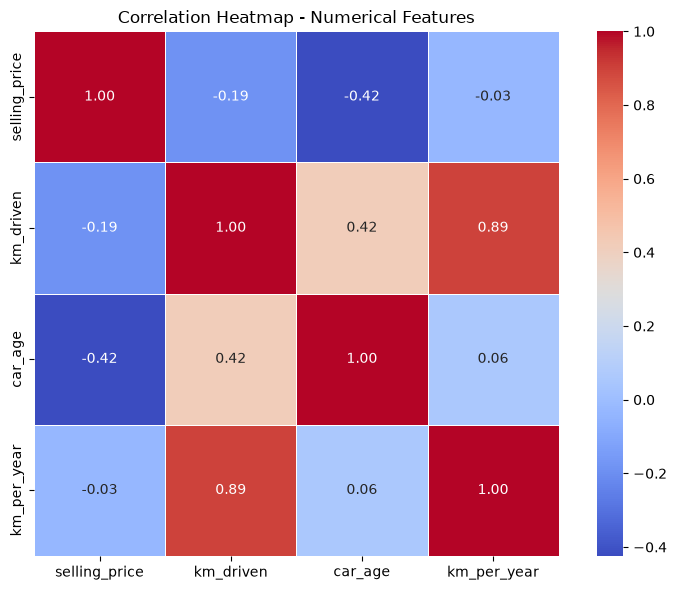

In [12]:


# Select only numerical columns for correlation
numeric_cols = ['selling_price', 'km_driven', 'car_age', 'km_per_year']
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, 
            annot=True,          # show correlation values
            cmap='coolwarm',     # color map
            fmt='.2f',           # 2 decimal places
            linewidths=0.5,
            square=True)
plt.title('Correlation Heatmap - Numerical Features')
plt.tight_layout()
plt.show()

#### Analysis: Correlation Heatmap

| Pair | Pearson r | Reading |
|---|---|---|
| selling_price vs car_age | −0.42 | Moderate negative: older cars sell for less. The strongest link with price here. |
| selling_price vs km_driven | −0.19 | Weak negative: more km lowers the price only a little. |
| selling_price vs km_per_year | −0.03 | ≈ 0: usage intensity has almost no linear effect on price. |
| km_driven vs car_age | 0.42 | Moderate positive: older cars have more km (saturating, see Section 2). |
| km_driven vs km_per_year | 0.89 | Very strong, but largely by construction, since `km_per_year` is derived from `km_driven`. |
| car_age vs km_per_year | 0.06 | ≈ 0: how hard a car is driven is unrelated to its age. |

- **Age matters more than mileage for price,** and neither is a strong predictor on its own (the largest |r| with price is only 0.42), so other attributes (brand/model, fuel, transmission, seller type) must explain much of the price variation, as the earlier sections suggest.
- **`km_per_year` is redundant with `km_driven`** (r = 0.89). Using both in a linear model would introduce multicollinearity; keep one, or use `km_per_year` only as a usage-intensity or outlier-detection feature.
- **Caveats.** Pearson correlation measures only linear relationships and is sensitive to outliers; because price is heavily skewed (Section 1), correlations with `log(selling_price)` would probably be cleaner. Correlation is not causation, and the categorical features are not included in this heatmap.

## Key Findings

*Based on 3,577 used-car listings (prices assumed to be in ₹).*

1. **Price is heavily right-skewed.** Most cars sell for well under ₹1M, with a thin luxury tail up to ≈ ₹9M. The log of price is close to a bell curve (centred at ≈ ₹0.27M–₹0.6M), so medians and log-price are the right tools for this data.
2. **Age is the strongest numeric driver of price, but a moderate one** (r = −0.42). Mileage is weaker (r = −0.19), and usage per year is essentially unrelated to price (r = −0.03).
3. **Mileage grows with age and then levels off.** Median km climbs by roughly 10–15k km per year up to ≈ 70k km at age 12, then plateaus at ≈ 80–90k km for cars aged 14–24. Counts at the oldest ages are small, so those points are noisy.
4. **Mileage alone does not set the price.** Cars above ≈ ₹2M almost never exceed ≈ 150k km, but premium diesel SUVs with 68k–100k km still sell for ₹4M–₹5.5M, while the cheapest cars are old budget models with low mileage.
5. **More owners means an older car.** Median age rises from 11 years (first owner) to 15, 16 and 18 years (second, third, fourth & above). First owners make up 62% of listings and second owners 27%.
6. **Seller type is linked to price.** Median price is ₹303,500 for individuals (79% of listings), ₹484,999 for dealers and ₹750,000 for Trustmark Dealers (only 33 cars).
7. **Diesel and automatic cars are priced highest.** Automatic diesel averages ≈ ₹1.7M versus ≈ ₹0.5M for manual diesel and ≈ ₹0.3M for manual petrol. LPG and CNG cars are the cheapest. Much of this gap is likely a premium-segment effect.
8. **`km_per_year` duplicates `km_driven`** (r = 0.89) and is unrelated to age (r = 0.06), so the two should not be used together in a linear model.
9. **Data-quality flags:** implausible odometer values (≈ 50 km/yr on a 20-year-old Jeep, ≈ 56,000 km/yr on a 10-year-old SX4, a car with ≈ 800k km), very small groups (Test Drive Car 17, Trustmark Dealer 33, electric cars, very old cars) and duplicated cells in the notebook.

## Conclusion

In this data set, a used car's price is shaped far more by **what the car is** (age, segment, fuel, transmission) and **who sells it** than by how far it has been driven. Cars lose value as they age (r = −0.42) while mileage adds only a small extra penalty (r = −0.19). Premium diesel automatics remain expensive even with 70k–100k km, and the cheapest cars are old, low-spec, multi-owner models.

Mileage, age and ownership count are closely tied together: older cars have been driven more, and have changed hands more often. Their effects on price therefore overlap and should be separated with a model, not read from one chart at a time.

